In [153]:
# imports
import sys
from pathlib import Path

import numpy as np
from scipy.stats import gaussian_kde

# Garante que a raiz do projeto esteja disponível para importação
raiz_projeto = Path.cwd().parent
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import math
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

import catalogo_variaveis
import unidades
import config

# Carga dos dados

In [154]:
df = pd.read_csv("../data/processed/dataset_soja.csv")

In [155]:
df.shape

(8934, 67)

In [156]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8934 entries, 0 to 8933
Data columns (total 67 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   localidade              8934 non-null   str    
 1   ano                     8934 non-null   int64  
 2   producao                8934 non-null   float64
 3   rendimento              8934 non-null   float64
 4   area_colhida            8934 non-null   float64
 5   area_plantada           8934 non-null   float64
 6   produto                 8934 non-null   str    
 7   cod_ibge                8934 non-null   int64  
 8   razao_colhida_plantada  8934 non-null   float64
 9   perda_flag              8934 non-null   int64  
 10  rendimento_calc         8934 non-null   float64
 11  rend_repetido           8934 non-null   int64  
 12  y_log                   8934 non-null   float64
 13  peso                    8934 non-null   float64
 14  implant_prec            8934 non-null   float64
 15

In [157]:
df.describe()

,ano,producao,rendimento,area_colhida,area_plantada,cod_ibge,razao_colhida_plantada,perda_flag,rendimento_calc,rend_repetido,...,argila,silte,prof_max_cm,n_perfis,lat,lon,solo_imputado,solo_dist_km,cad_mm,lag1_rel
count,8934.000000,8934.000000,8934.000000,8934.000000,8934.000000,8.934000e+03,8934.000000,8934.000000,8934.000000,8934.000000,...,7982.000000,7982.000000,7982.000000,1495.000000,8934.000000,8934.000000,8934.000000,8934.000000,8934.000000,7961.000000
mean,2014.072644,7169.701589,2790.053280,2364.676964,2371.532796,3.528799e+06,0.998335,0.003358,2790.079215,0.451198,...,326.208991,82.520337,106.687108,11.931773,-21.813639,-49.105067,0.832662,43.997624,84.057934,-0.009560
std,7.566059,19141.760281,661.586181,5688.968984,5704.916056,1.654537e+04,0.029653,0.057854,661.574681,0.497640,...,156.003265,51.923071,42.486322,39.129766,1.068733,1.393255,0.373298,28.150562,19.953006,0.213604
min,2000.000000,15.000000,800.000000,10.000000,10.000000,3.500105e+06,0.150000,0.000000,800.000000,0.000000,...,18.000000,2.000000,20.000000,2.000000,-24.772000,-52.836900,0.000000,0.000000,18.090000,-1.203973
25%,2007.000000,463.250000,2400.000000,200.000000,200.000000,3.514957e+06,1.000000,0.000000,2400.000000,0.000000,...,215.500000,45.166667,75.833333,4.000000,-22.651600,-50.200200,1.000000,24.702710,75.020000,-0.117783
50%,2015.000000,1484.500000,2719.500000,540.000000,544.000000,3.529203e+06,1.000000,0.000000,2719.641816,0.000000,...,317.333333,73.500000,101.666667,6.000000,-21.735850,-49.142500,1.000000,46.058412,82.358222,0.000000
75%,2021.000000,5400.000000,3194.500000,1955.000000,1967.500000,3.543204e+06,1.000000,0.000000,3194.871795,1.000000,...,438.333333,114.000000,137.500000,8.000000,-20.940500,-47.938500,1.000000,63.215307,96.366667,0.130736
max,2025.000000,360000.000000,5400.000000,82000.000000,82000.000000,3.557303e+06,1.000000,1.000000,5400.000000,1.000000,...,762.500000,321.000000,450.000000,310.000000,-19.907300,-45.060000,1.000000,116.777435,137.200000,0.765654


In [158]:
df.describe(include="object")

C:\Users\Samsung\AppData\Local\Temp\ipykernel_34252\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,localidade,produto
count,8934,8934
unique,521,1
top,Aguaí - SP,soja
freq,26,8934


In [159]:
df.loc[df["ano"] >= 2022]

,localidade,ano,producao,rendimento,area_colhida,area_plantada,produto,cod_ibge,razao_colhida_plantada,perda_flag,...,argila,silte,prof_max_cm,n_perfis,lat,lon,solo_imputado,solo_dist_km,cad_mm,lag1_rel
7036,Adamantina - SP,2022,1034.0,2068.0,500.0,500.0,soja,3500105,1.0,0,...,117.333333,14.166667,65.000000,NaN,-21.5767,-51.0568,1,46.306230,46.206333,0.000000
7037,Adolfo - SP,2022,3673.0,3601.0,1020.0,1020.0,soja,3500204,1.0,0,...,215.500000,19.166667,143.333333,NaN,-21.2887,-49.6533,1,63.215307,79.540000,-0.356675
7038,Aguaí - SP,2022,11127.0,3709.0,3000.0,3000.0,soja,3500303,1.0,0,...,449.000000,113.666667,88.000000,NaN,-22.0500,-47.0403,1,29.899939,96.412800,0.180653
7039,Agudos - SP,2022,2363.0,3501.0,675.0,675.0,soja,3500709,1.0,0,...,271.666667,72.666667,107.000000,NaN,-22.5719,-49.1088,1,47.005544,90.453333,0.200762
7040,Alambari - SP,2022,7260.0,3300.0,2200.0,2200.0,soja,3500758,1.0,0,...,160.000000,40.000000,87.500000,2.0,-23.5489,-47.8691,0,0.000000,67.900000,0.139762
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8929,Águas de Santa Bárbara - SP,2025,35778.0,4061.0,8810.0,8810.0,soja,3500550,1.0,0,...,292.666667,67.500000,102.500000,NaN,-22.8580,-49.2610,1,58.814446,91.513333,0.060014
8930,Álvares Florence - SP,2025,6480.0,3600.0,1800.0,1800.0,soja,3501202,1.0,0,...,438.333333,143.666667,73.333333,NaN,-20.2896,-49.9203,1,56.954996,82.358222,-0.169076
8931,Álvares Machado - SP,2025,112.0,2240.0,50.0,50.0,soja,3501301,1.0,0,...,NaN,NaN,NaN,NaN,-22.1315,-51.5149,1,81.863877,80.000000,-0.146097
8932,Álvaro de Carvalho - SP,2025,200.0,2000.0,100.0,100.0,soja,3501400,1.0,0,...,106.666667,62.833333,82.333333,NaN,-22.0865,-49.7340,1,21.086588,62.633711,-0.300105


# Análise das variáveis numéricas

## Qualidade dos dados

In [160]:
def plot_missing_values(df, figsize=(12, 6)):
    missing_pct = df.isnull().mean().mul(100).sort_values(ascending=False)

    missing_pct = missing_pct[missing_pct > 0]

    if missing_pct.empty:
        print("Nenhuma feature possui valores ausentes.")
        return

    plt.figure(figsize=figsize)

    ax = sns.barplot(x=missing_pct.values, y=missing_pct.index, color="steelblue")

    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

    plt.title("Porcentagem de Valores Ausentes por Feature")
    plt.xlabel("Valores ausentes (%)")
    plt.ylabel("Features")
    plt.xlim(0, min(100, missing_pct.max() * 1.15))
    plt.tight_layout()
    plt.show()

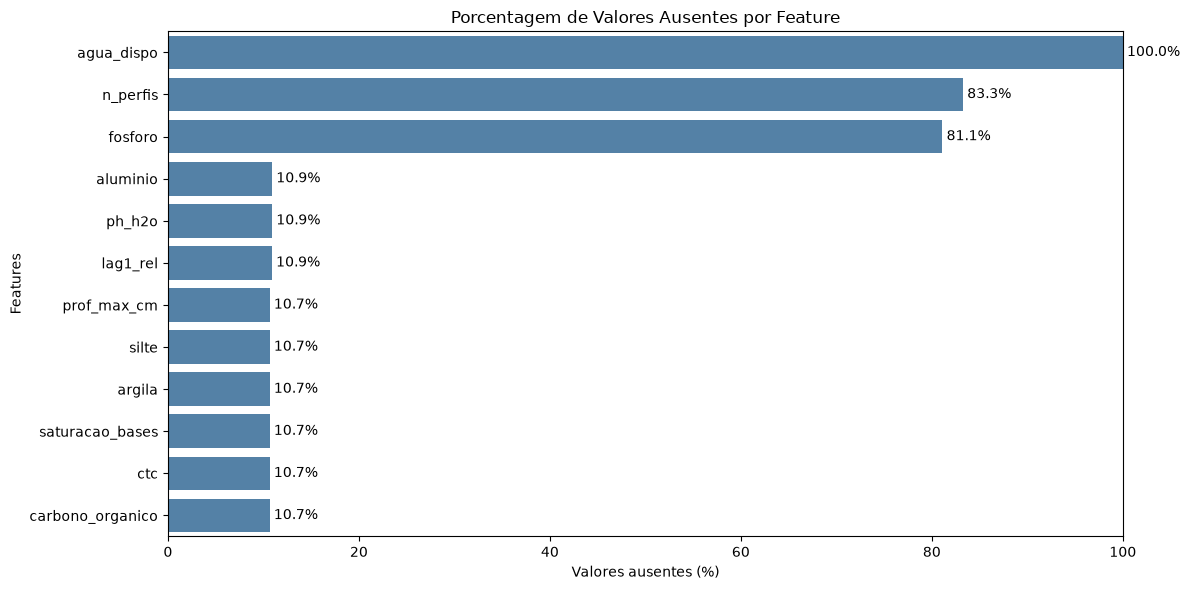

In [161]:
plot_missing_values(df)

In [162]:
# Dropando colunas com mais de 30% de valores ausentes
df.drop(columns=df.columns[df.isnull().mean() > 0.30], inplace=True)

In [163]:
def analyze_missing_rows(df, threshold=0.30):
    missing_count = df.isnull().sum(axis=1)
    missing_pct = df.isnull().mean(axis=1) * 100

    result = pd.DataFrame(
        {
            "linha": df.index,
            "features_ausentes": missing_count.values,
            "features_ausentes_pct": missing_pct.values,
        }
    )

    result = (
        result[result["features_ausentes_pct"] > threshold * 100]
        .sort_values("features_ausentes_pct", ascending=False)
        .reset_index(drop=True)
    )

    print(f"Total de linhas: {len(df)}")
    print(f"Linhas com mais de {threshold:.0%} de features ausentes: {len(result)}")
    print(f"Percentual das linhas: {len(result) / len(df) * 100:.2f}%")

    return result

In [164]:
df_missing_rows = analyze_missing_rows(df, threshold=0.10)

display(df_missing_rows)

Total de linhas: 8934
Linhas com mais de 10% de features ausentes: 952
Percentual das linhas: 10.66%


,linha,features_ausentes,features_ausentes_pct
0,806,9,14.0625
1,818,9,14.0625
2,86,9,14.0625
3,1193,9,14.0625
4,13,9,14.0625
...,...,...,...
947,8871,8,12.5000
948,674,8,12.5000
949,8898,8,12.5000
950,8903,8,12.5000


In [165]:
# Dropping enchimento_dias_geada_d
df.drop(columns=["enchimento_dias_geada"], inplace=True)

## Univariada

In [166]:
columns_to_plot = [
    "ano",
    "producao_t",
    "rendimento_kg_ha",
    "area_colhida_ha",
    "area_plantada_ha",
    "peso",
]

columns_to_plot_implant = [
    "implant_prec",
    "implant_tmax",
    "implant_tmin",
    "implant_rad",
    "implant_defic",
    "implant_estresse",
    "implant_dias_calor",
    "implant_dias_geada",
    "implant_seca_max",
    "implant_gd",
    "implant_umsolo",
]

In [167]:
def plot_histograms_kde(df, columns, bins=30, ncols=2):
    nrows = math.ceil(len(columns) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False
    )
    axes = axes.flatten()

    for ax, col in zip(axes, columns):
        data = df[col].dropna()

        if data.empty:
            ax.set_title(f"Sem dados: {col}")
            continue

        q1 = data.quantile(0.25)
        q3 = data.quantile(0.75)
        iqr = q3 - q1
        limite_superior = q3 + 3.5 * iqr

        x_min = data.min()
        data_filtrada = data[data <= limite_superior]
        bins_range = np.linspace(x_min, limite_superior, bins + 1)

        ax.hist(
            data_filtrada,
            bins=bins_range,
            density=True,
            color="skyblue",
            edgecolor="black",
            alpha=0.6,
            label="Histograma",
        )

        if len(data_filtrada) > 1 and data_filtrada.nunique() > 1:
            kde = gaussian_kde(data_filtrada)
            x = np.linspace(x_min, limite_superior, 300)
            ax.plot(x, kde(x), color="red", linewidth=2, label="KDE")

        media = data_filtrada.mean()
        mediana = data_filtrada.median()

        ax.axvline(
            media,
            color="blue",
            linestyle="--",
            linewidth=2,
            label=f"Média: {media:.2f}",
        )
        ax.axvline(
            mediana,
            color="green",
            linestyle="-.",
            linewidth=2,
            label=f"Mediana: {mediana:.2f}",
        )

        ax.set_xlim(x_min, limite_superior)
        ax.set_title(f"Distribuição de {col}")
        ax.set_xlabel(col)
        ax.set_ylabel("Densidade")
        ax.legend()

    for ax in axes[len(columns) :]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

In [168]:
original_columns = df.columns.tolist()
df = unidades.para_exportacao(df)

In [169]:
df.describe()

,ano,producao_t,rendimento_kg_ha,area_colhida_ha,area_plantada_ha,cod_ibge,razao_colhida_plantada,perda_flag,rendimento_calc_kg_ha,rend_repetido,...,aluminio_cmolc_dm3,argila_g_kg,silte_g_kg,prof_max_cm,lat,lon,solo_imputado,solo_dist_km,cad_mm,lag1_rel
count,8934.000000,8934.000000,8934.000000,8934.000000,8934.000000,8.934000e+03,8934.000000,8934.000000,8934.000000,8934.000000,...,7959.000000,7982.000000,7982.000000,7982.000000,8934.000000,8934.000000,8934.000000,8934.000000,8934.000000,7961.000000
mean,2014.072644,7169.701589,2790.053280,2364.676964,2371.532796,3.528799e+06,0.998335,0.003358,2790.079215,0.451198,...,1.415279,326.208991,82.520337,106.687108,-21.813639,-49.105067,0.832662,43.997624,84.057934,-0.009560
std,7.566059,19141.760281,661.586181,5688.968984,5704.916056,1.654537e+04,0.029653,0.057854,661.574681,0.497640,...,1.691056,156.003265,51.923071,42.486322,1.068733,1.393255,0.373298,28.150562,19.953006,0.213604
min,2000.000000,15.000000,800.000000,10.000000,10.000000,3.500105e+06,0.150000,0.000000,800.000000,0.000000,...,0.000000,18.000000,2.000000,20.000000,-24.772000,-52.836900,0.000000,0.000000,18.090000,-1.203973
25%,2007.000000,463.250000,2400.000000,200.000000,200.000000,3.514957e+06,1.000000,0.000000,2400.000000,0.000000,...,0.480000,215.500000,45.166667,75.833333,-22.651600,-50.200200,1.000000,24.702710,75.020000,-0.117783
50%,2015.000000,1484.500000,2719.500000,540.000000,544.000000,3.529203e+06,1.000000,0.000000,2719.641816,0.000000,...,1.021667,317.333333,73.500000,101.666667,-21.735850,-49.142500,1.000000,46.058412,82.358222,0.000000
75%,2021.000000,5400.000000,3194.500000,1955.000000,1967.500000,3.543204e+06,1.000000,0.000000,3194.871795,1.000000,...,1.710000,438.333333,114.000000,137.500000,-20.940500,-47.938500,1.000000,63.215307,96.366667,0.130736
max,2025.000000,360000.000000,5400.000000,82000.000000,82000.000000,3.557303e+06,1.000000,1.000000,5400.000000,1.000000,...,21.000000,762.500000,321.000000,450.000000,-19.907300,-45.060000,1.000000,116.777435,137.200000,0.765654


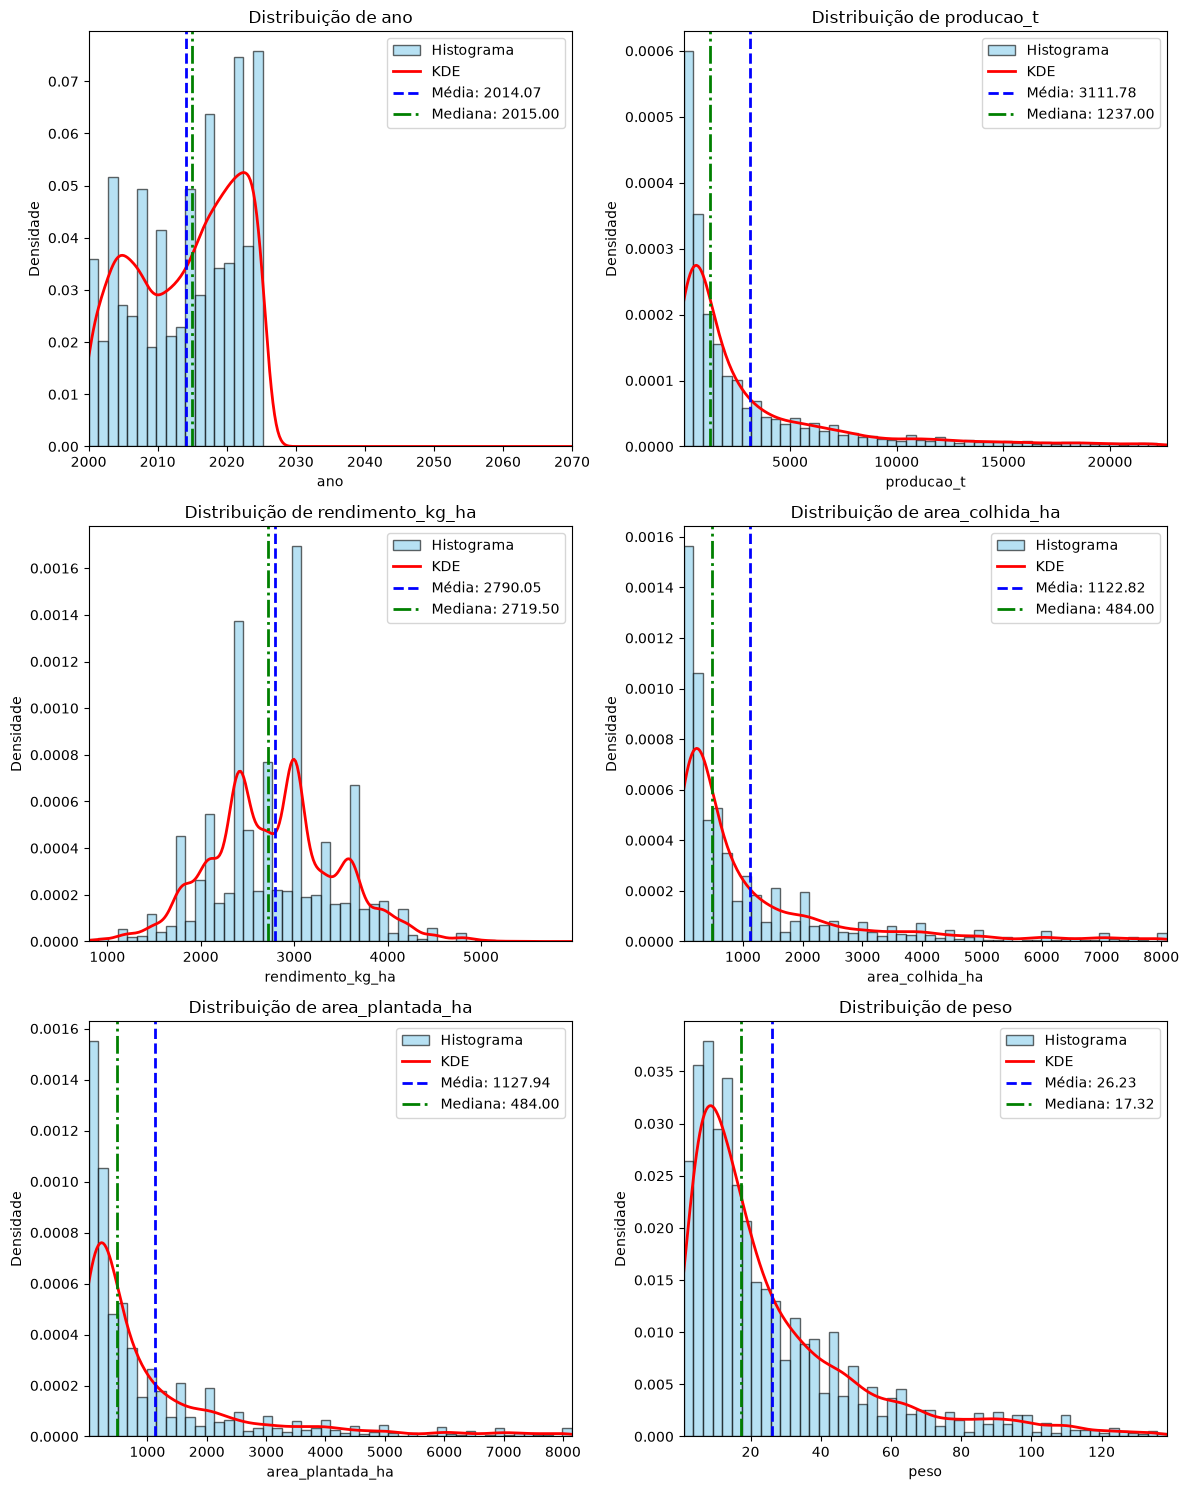

In [170]:
plot_histograms_kde(df, columns_to_plot, bins=50, ncols=2)

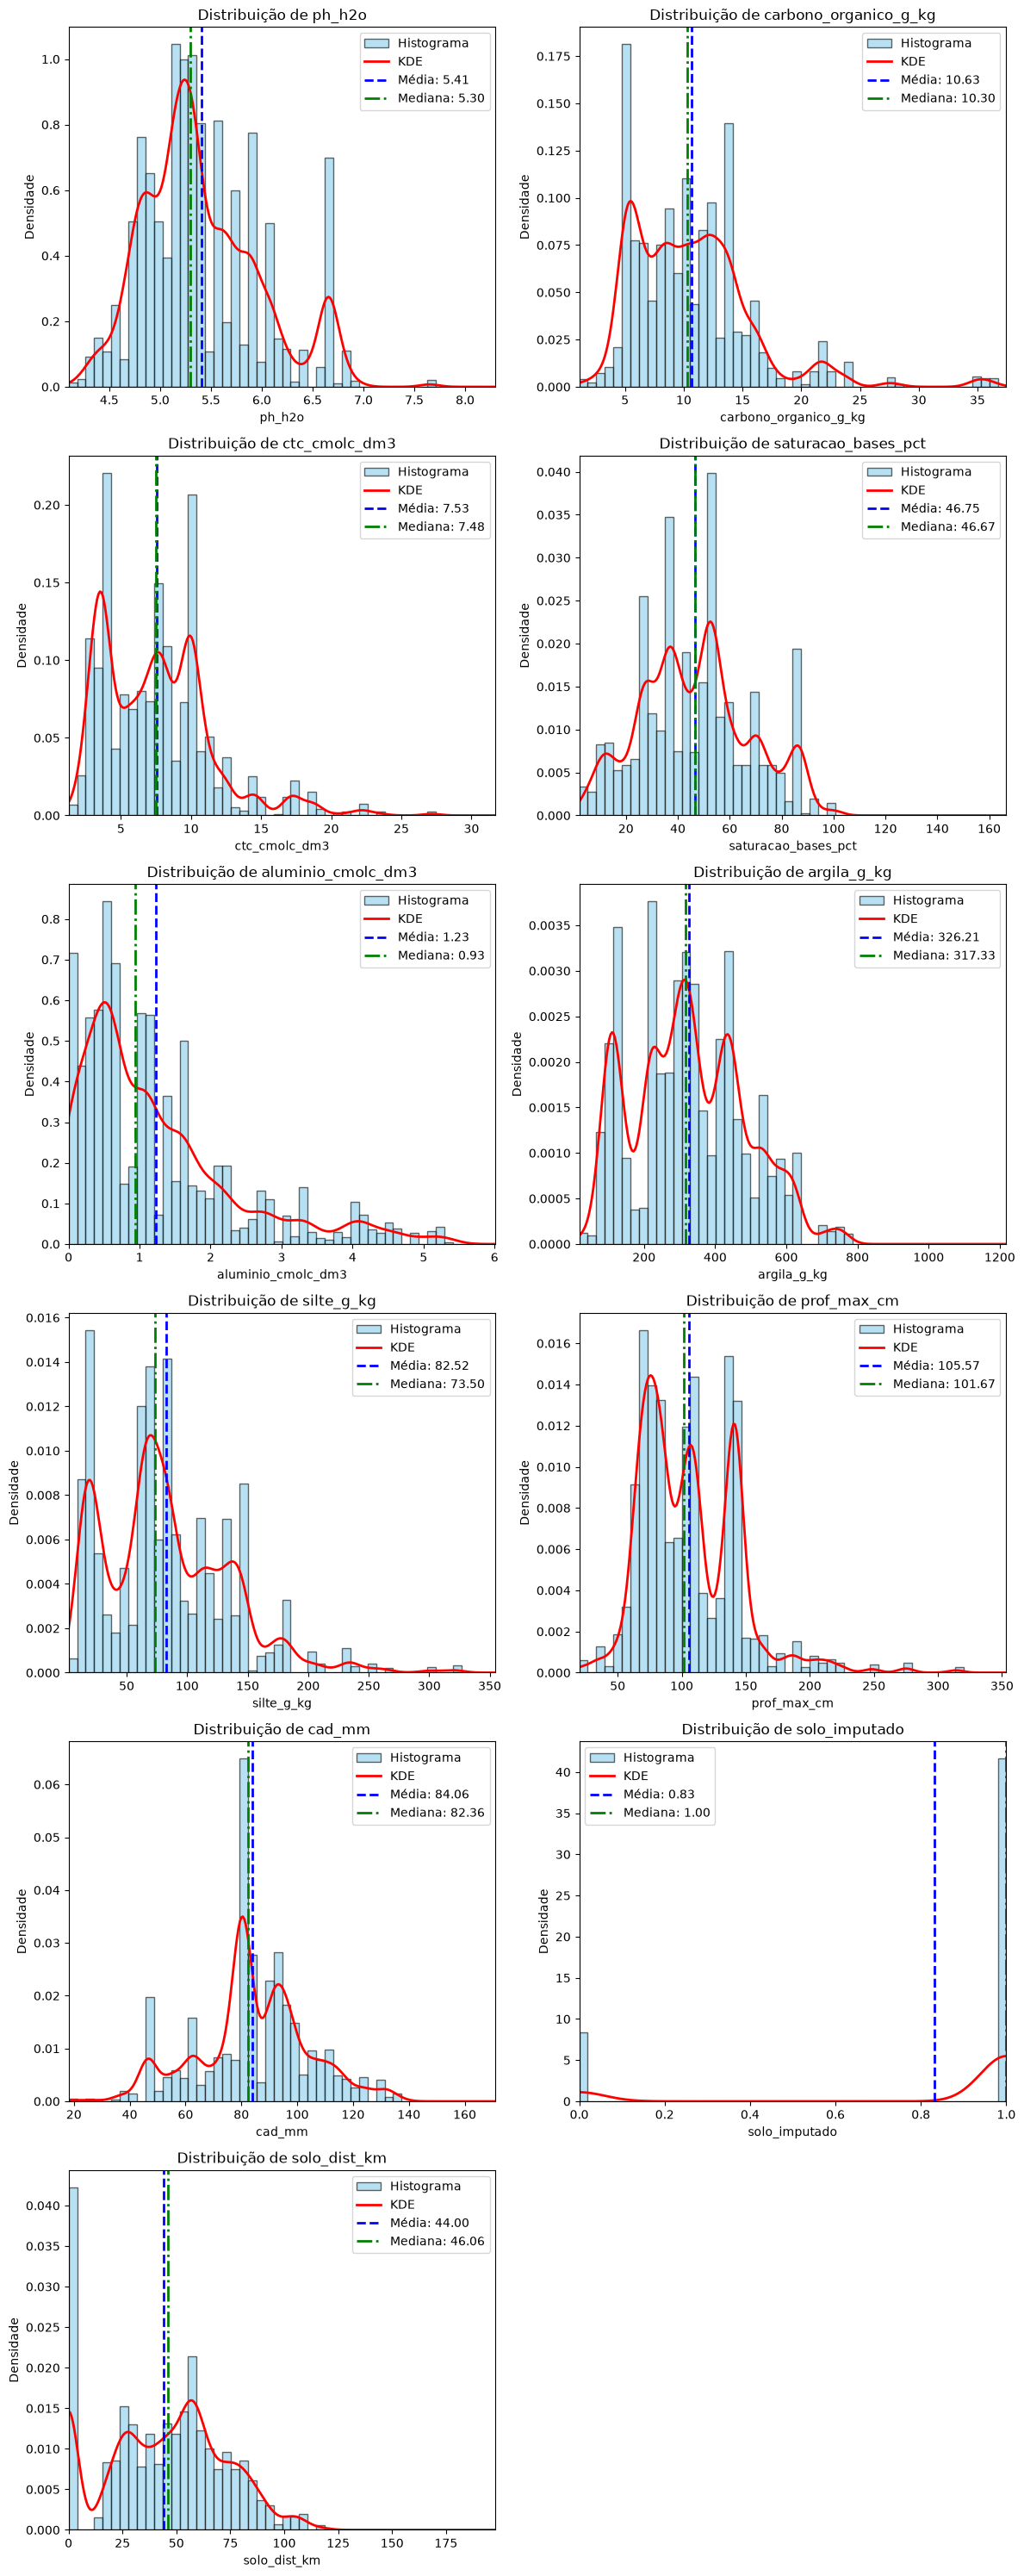

In [171]:
plot_histograms_kde(
    df, [x for x in catalogo_variaveis.SOLO if x in df.columns], bins=50, ncols=2
)

In [172]:
columns_to_plot_clim = [
    f"enchimento_{i}"
    for i in catalogo_variaveis.CLIMA_INDICADORES
    if f"enchimento_{i}" in df.columns
]

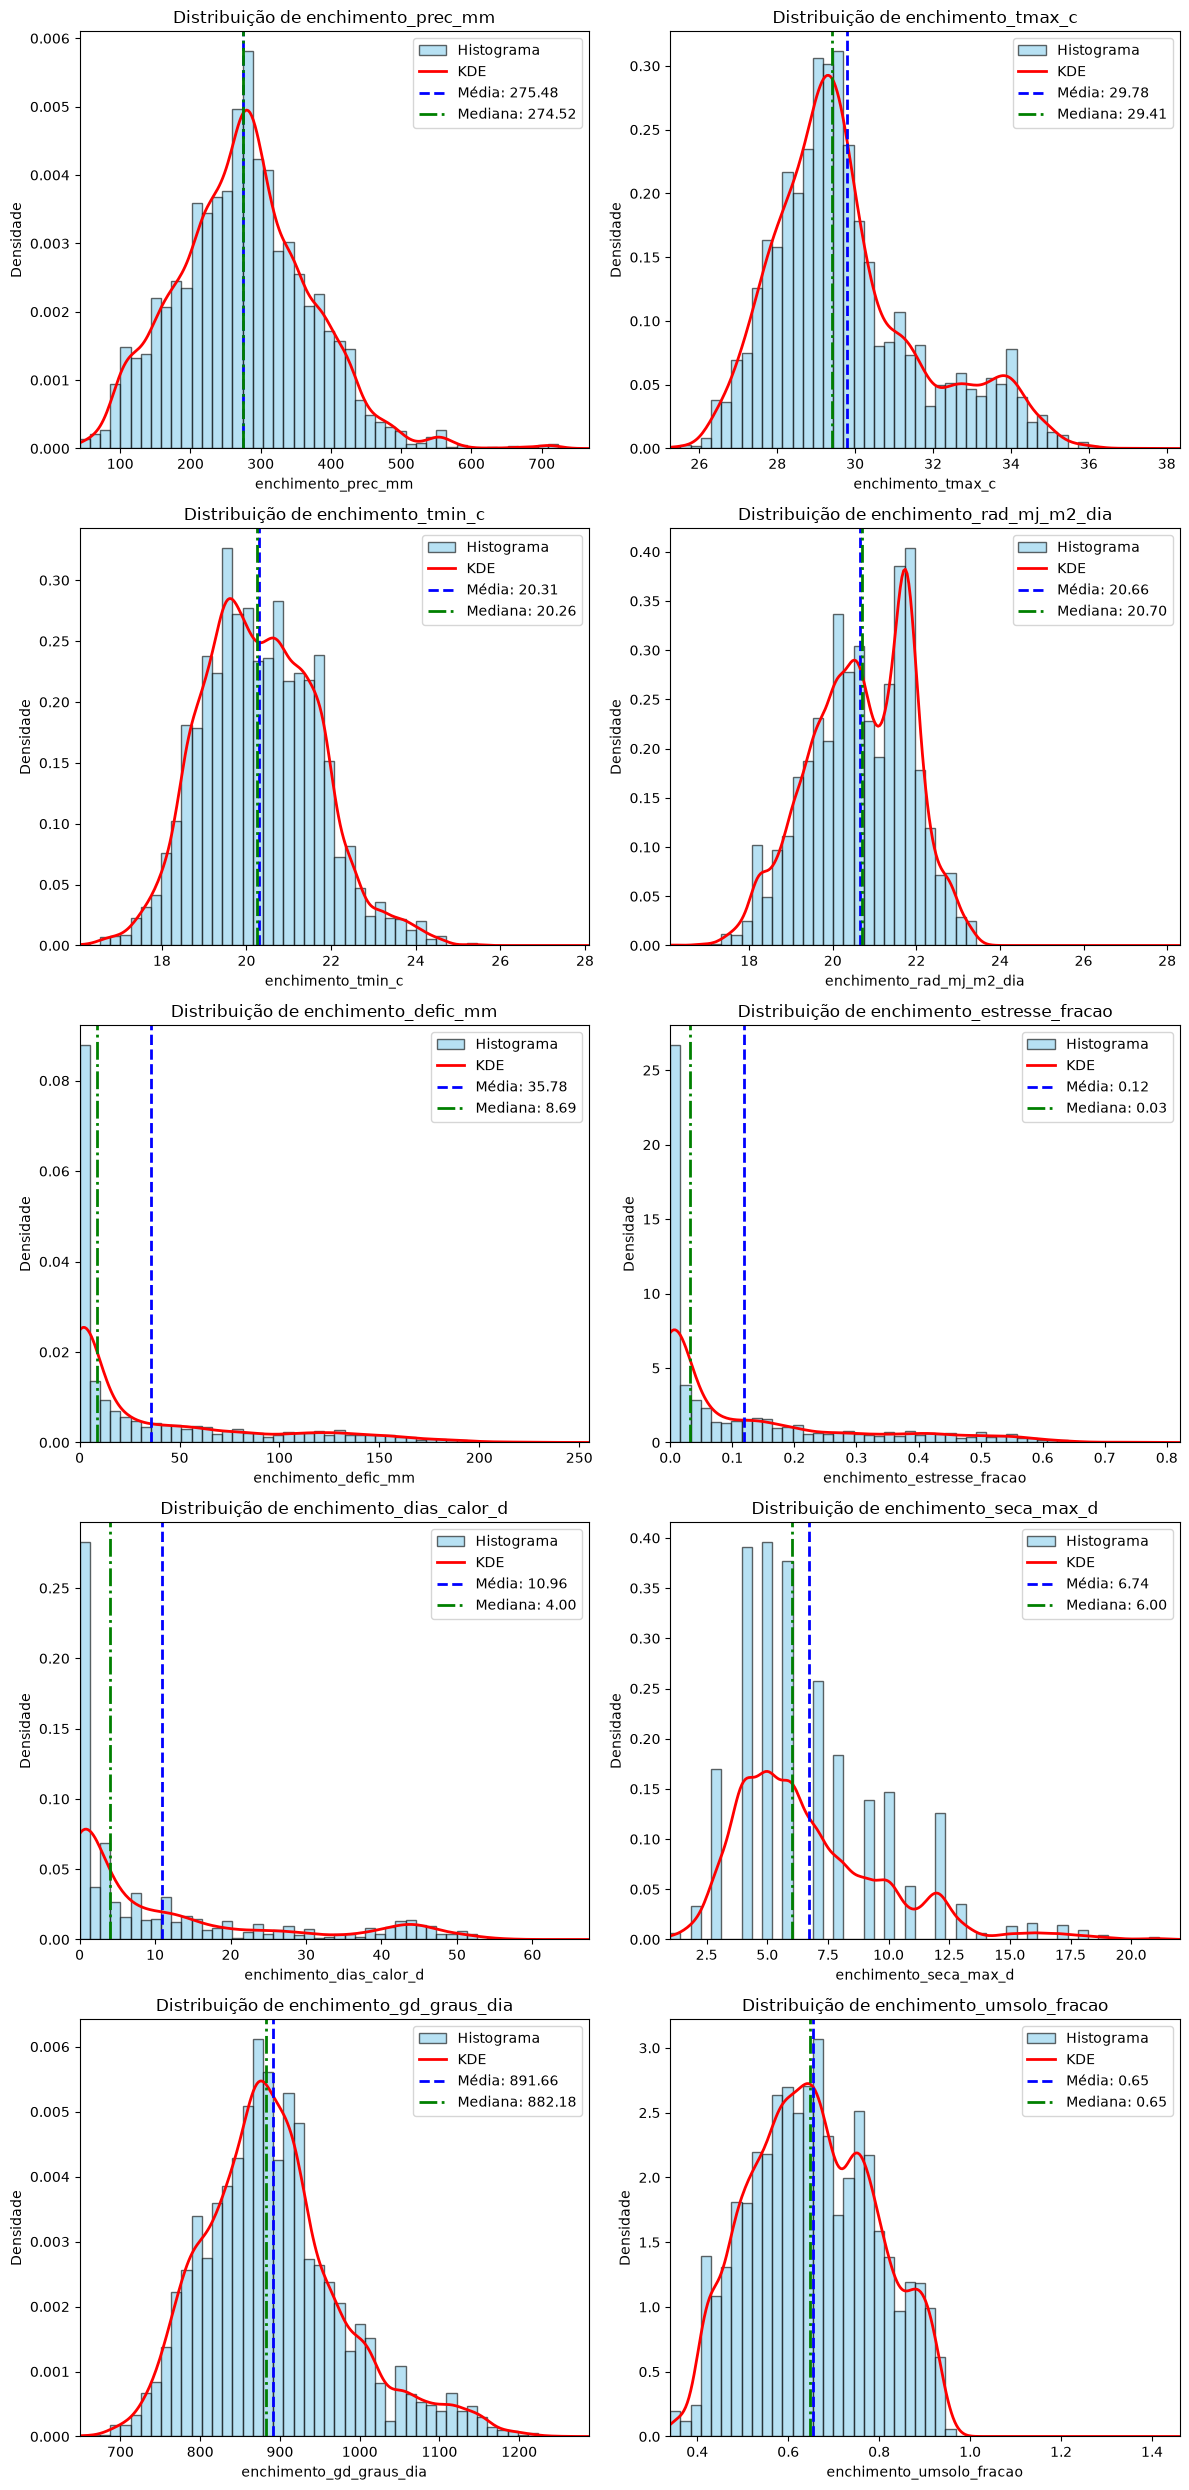

In [173]:
plot_histograms_kde(df, columns_to_plot_clim, bins=50, ncols=2)

In [174]:
def plot_boxplots(df, columns, ncols=2, showfliers=True):
    nrows = math.ceil(len(columns) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False
    )
    axes = axes.flatten()

    for ax, col in zip(axes, columns):
        data = df[col].dropna()

        if data.empty:
            ax.set_title(f"Sem dados: {col}")
            continue

        ax.boxplot(
            data,
            vert=True,
            patch_artist=True,
            showfliers=showfliers,
            boxprops=dict(facecolor="skyblue", edgecolor="black"),
            medianprops=dict(color="red", linewidth=2),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black"),
            flierprops=dict(
                marker="o",
                markerfacecolor="orange",
                markeredgecolor="black",
                markersize=4,
                alpha=0.6,
            ),
        )

        ax.set_title(f"Boxplot de {col}")
        ax.set_ylabel(col)
        ax.set_xticks([])

    for ax in axes[len(columns) :]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

C:\Users\Samsung\AppData\Local\Temp\ipykernel_34252\1819569262.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\ipykernel_34252\1819569262.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\ipykernel_34252\1819569262.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\ipykernel_34252\1819569262.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\

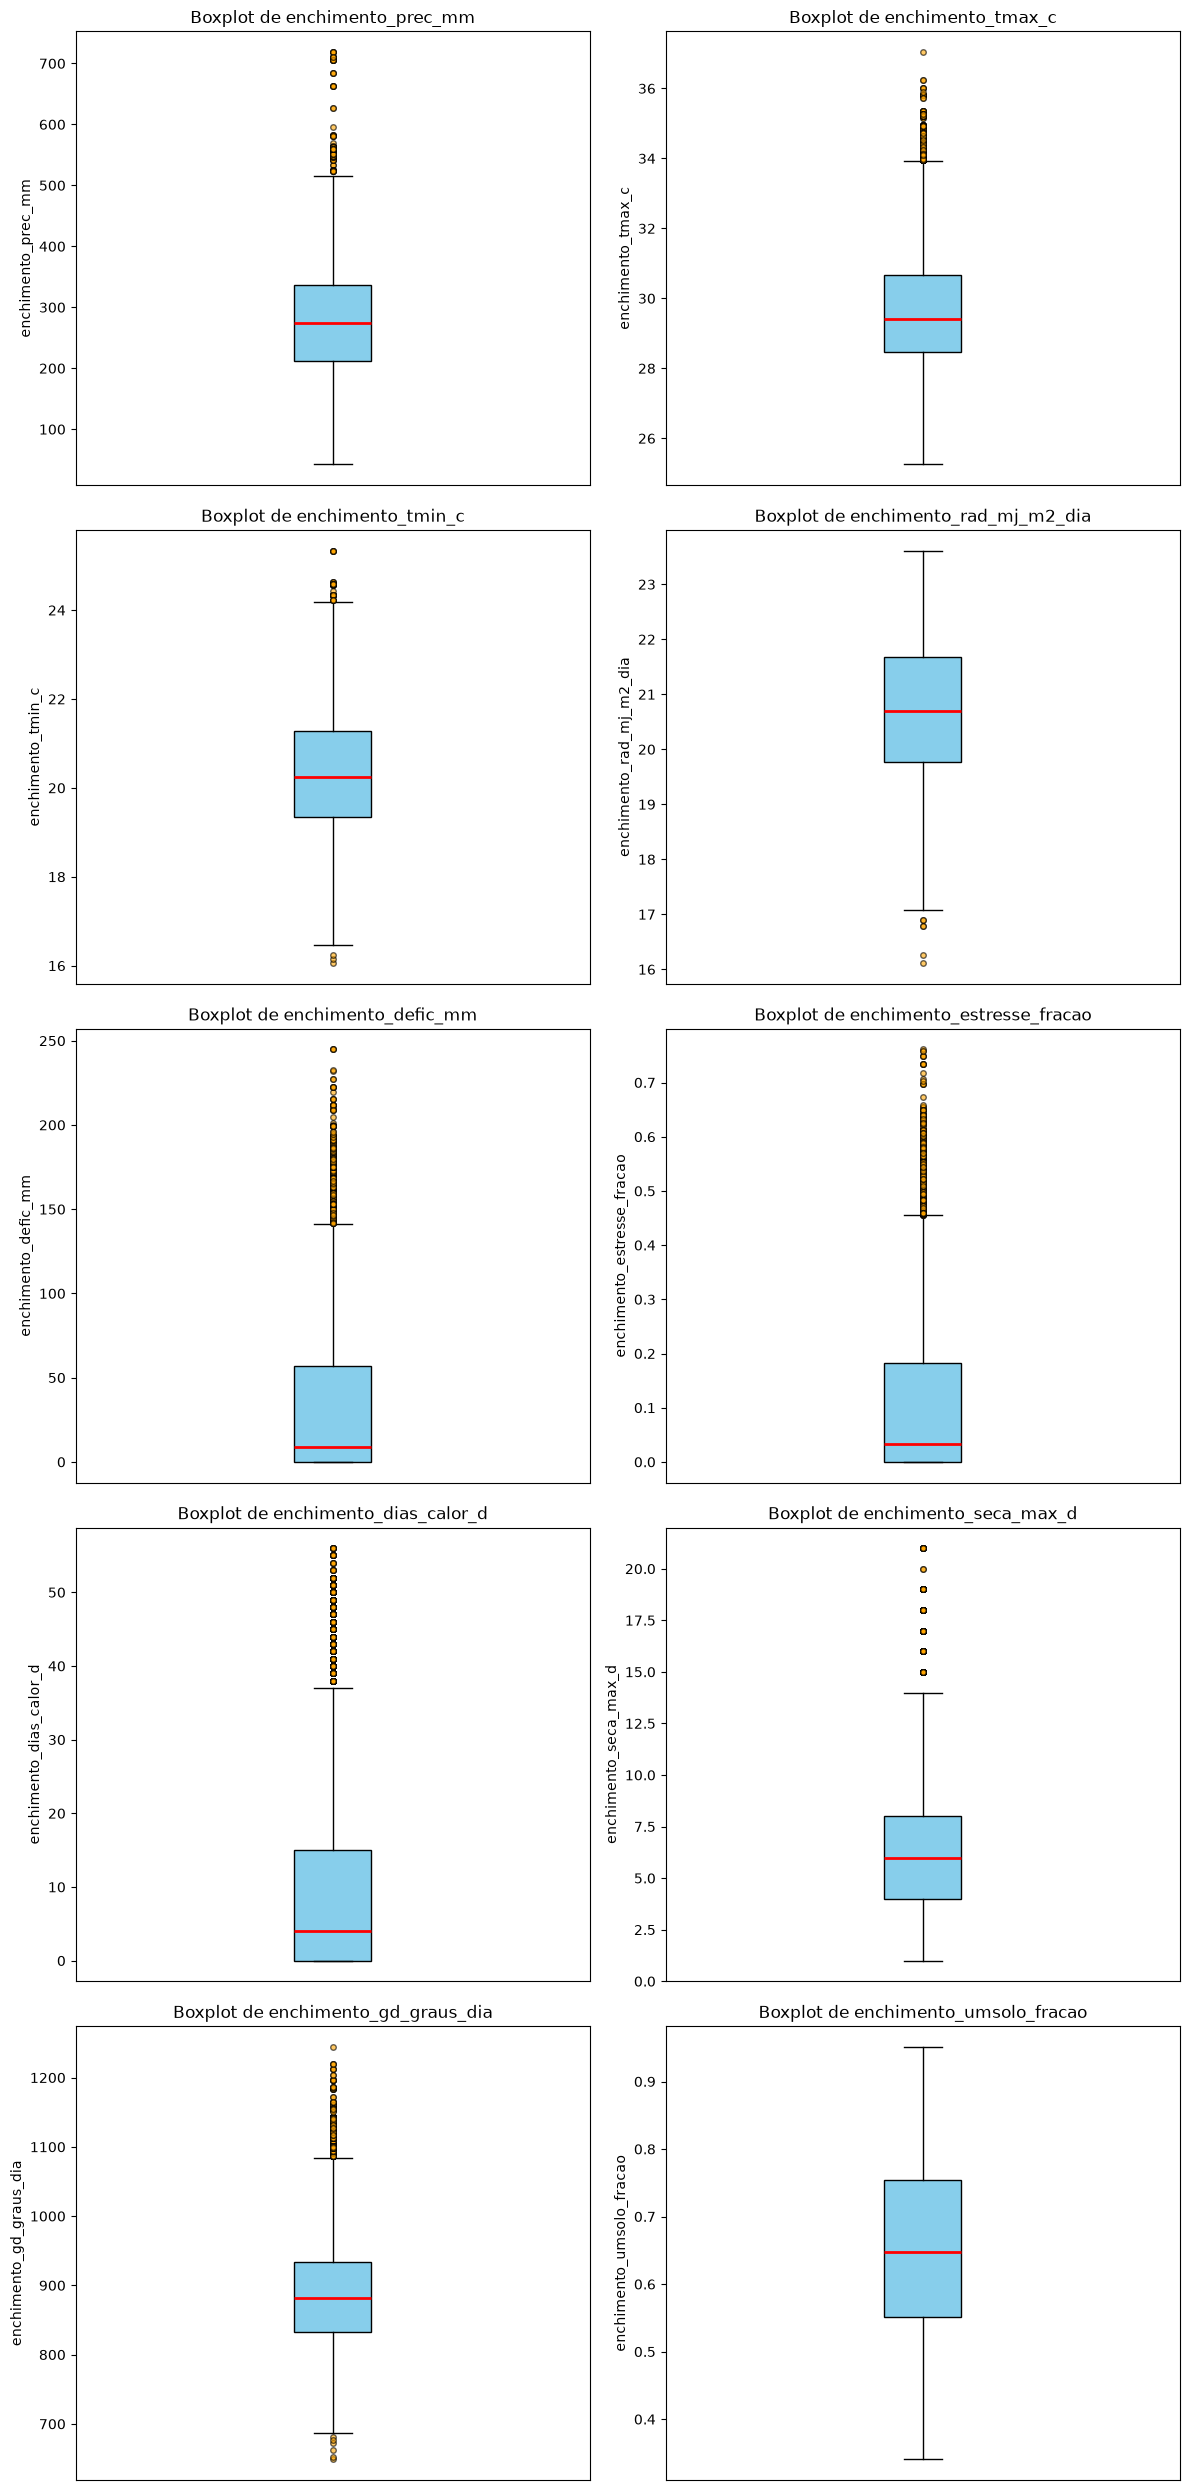

In [175]:
plot_boxplots(df, columns_to_plot_clim, ncols=2)

In [176]:
# Dropando colunas com menos de 80% de preenchimento
df_eda = df.copy()
df_eda.dropna(axis=1, thresh=int(0.8 * len(df_eda)), inplace=True)

# Análise multivariada

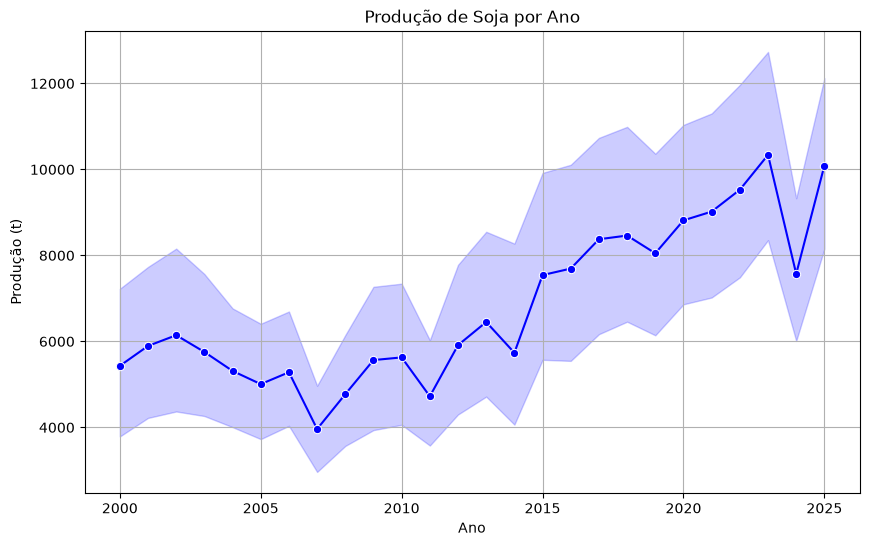

In [177]:
# produção por ano

plt.figure(figsize=(10, 6))

sns.lineplot(data=df, x="ano", y="producao_t", marker="o", color="blue")

plt.title("Produção de Soja por Ano")
plt.xlabel("Ano")
plt.ylabel("Produção (t)")
plt.grid()

Há uma clara tendencia de crescimento da produção ao longo do tempo. Essa é uma tendencia natural devido ao desenvolvimento tecnologico e aquecimento do clima

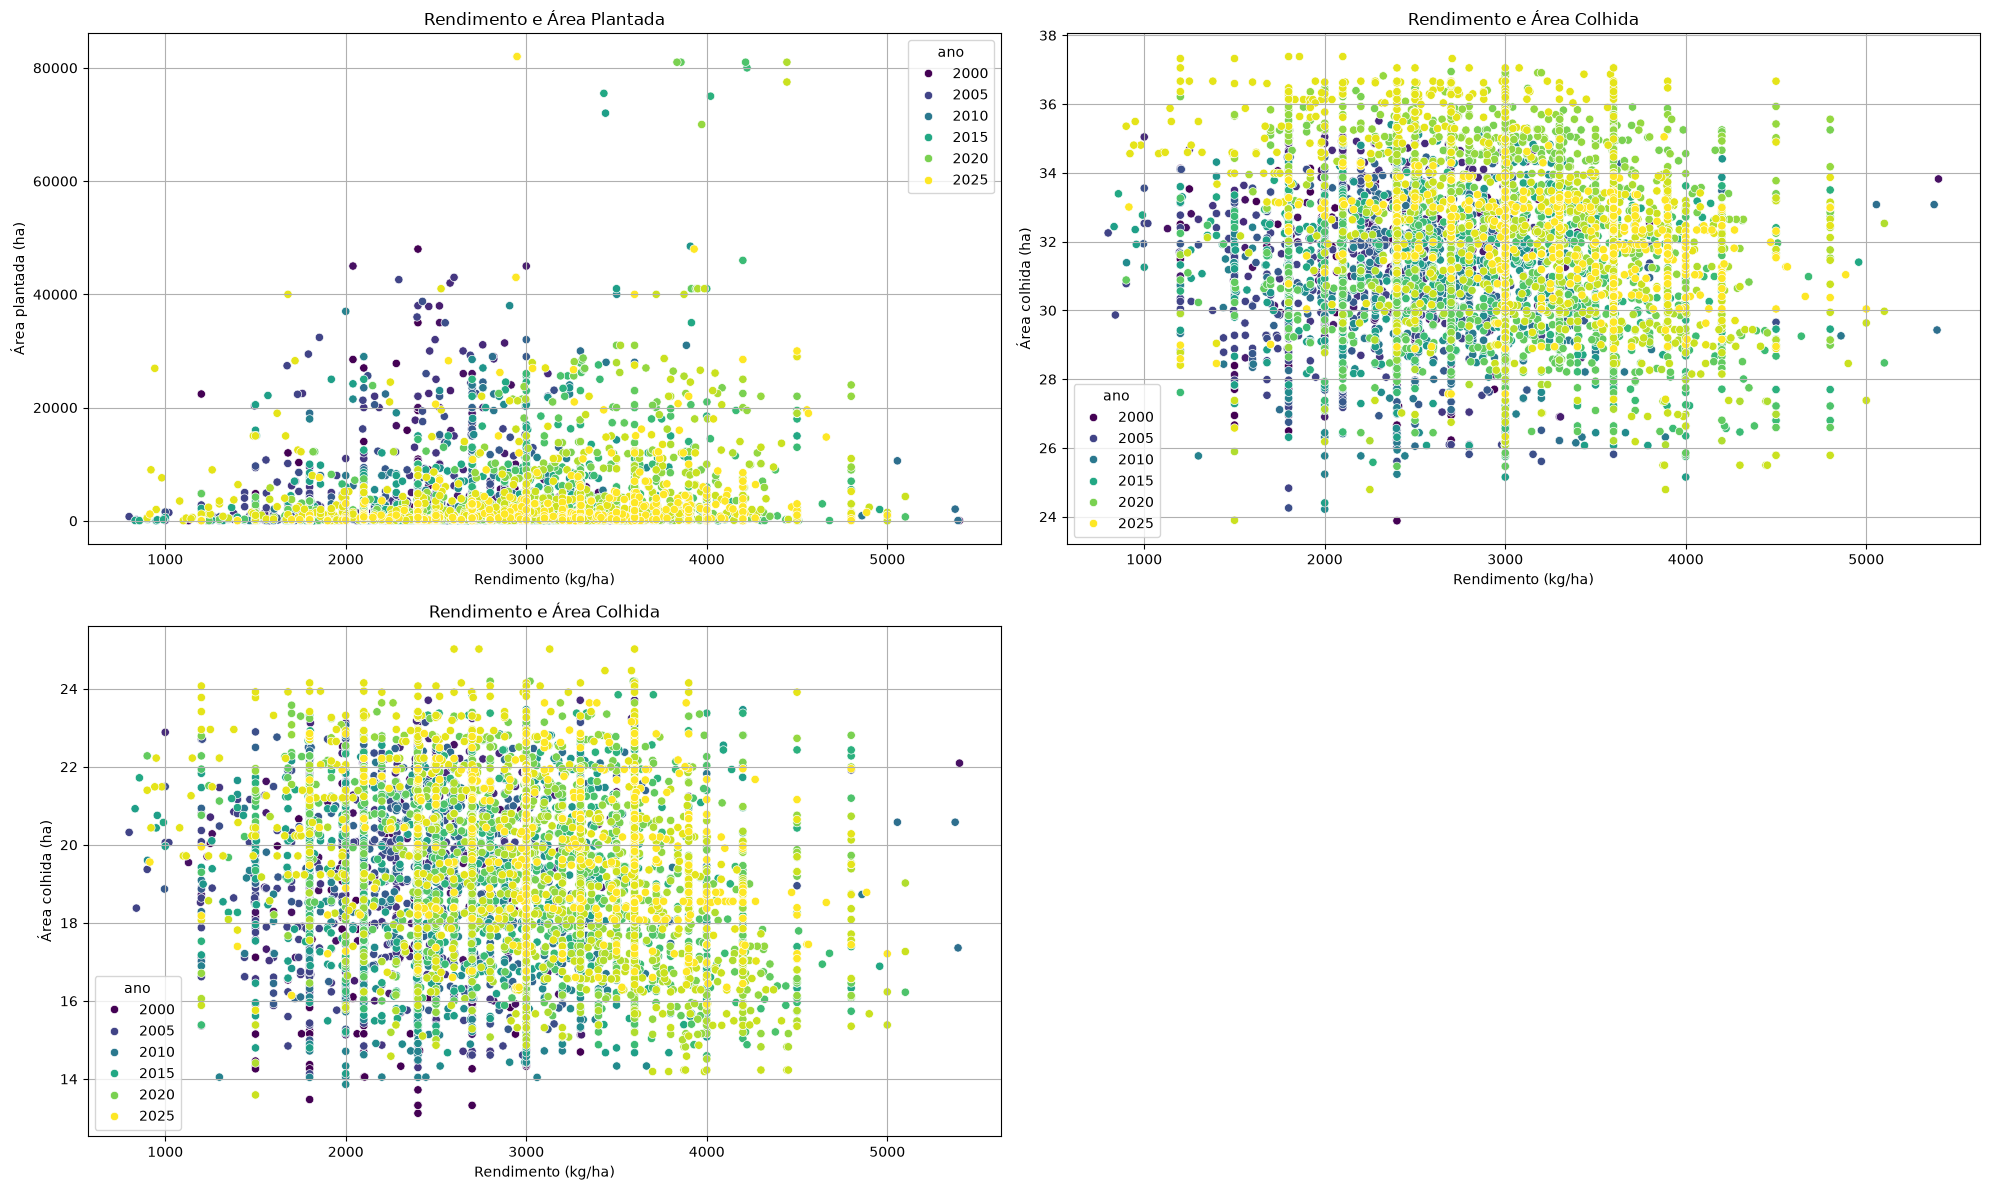

In [178]:
# relação area plantada e colhida


def plot_scatter_subplots(df, plots, ncols=2):
    nrows = math.ceil(len(plots) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(10 * ncols, 6 * nrows), squeeze=False
    )
    axes = axes.ravel()

    for ax, (x, y, title, xlabel, ylabel) in zip(axes, plots):
        sns.scatterplot(
            data=df,
            x=x,
            y=y,
            marker="o",
            hue="ano",
            palette="viridis",
            ax=ax,
        )

        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid()

    for ax in axes[len(plots) :]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()


plot_scatter_subplots(
    df,
    [
        (
            "rendimento_kg_ha",
            "area_plantada_ha",
            "Rendimento e Área Plantada",
            "Rendimento (kg/ha)",
            "Área plantada (ha)",
        ),
        (
            "rendimento_kg_ha",
            "implant_tmax_c",
            "Rendimento e Área Colhida",
            "Rendimento (kg/ha)",
            "Área colhida (ha)",
        ),
        (
            "rendimento_kg_ha",
            "implant_tmin_c",
            "Rendimento e Área Colhida",
            "Rendimento (kg/ha)",
            "Área colhida (ha)",
        ),
    ],
)

Não há uma discriminação clara associada à relação entre a area plantada e o rendimento. Surge a hipótese que há outros fatores que influenciam um melhor rendimento. 

In [179]:
def plot_correlation_by_year(df, columns, year_col="ano", year=None):
    if year is not None:
        data = df.loc[df[year_col] == year, columns]
    else:
        data = df[columns]

    plt.figure(figsize=(10, 10))

    sns.heatmap(
        data.corr(numeric_only=True),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
    )

    title = (
        f"Correlação entre features — {year}"
        if year is not None
        else "Correlação entre features"
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()

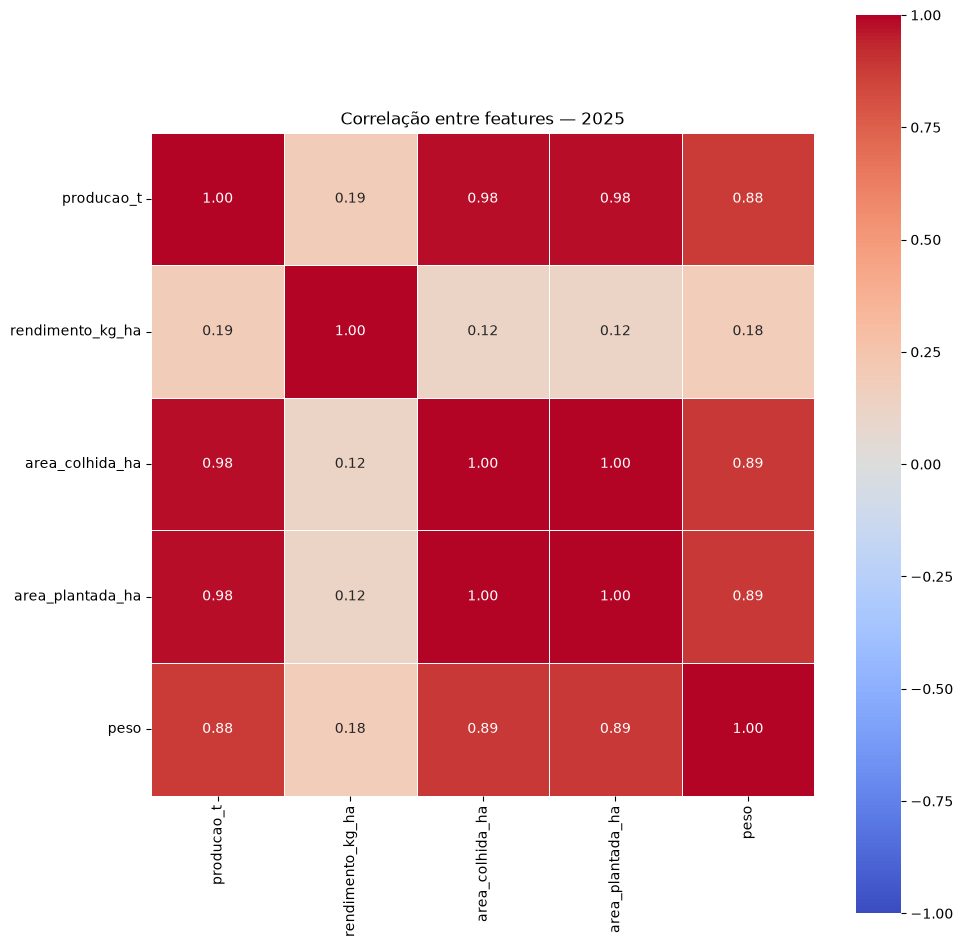

In [180]:
columns = [
    "producao_t",
    "rendimento_kg_ha",
    "area_colhida_ha",
    "area_plantada_ha",
    "peso",
]

plot_correlation_by_year(df, columns, year_col="ano", year=2025)

# Modelo

In [187]:
from sklearn.model_selection import train_test_split


# Definição do target e features
df.columns = original_columns
X = df.columns.difference(config.COLS_VAZAMENTO)
Y = "rendimento"

In [189]:
df_train, df_temp = train_test_split(df, test_size=0.30, random_state=42)
df_val, df_test = train_test_split(df_temp, test_size=0.50, random_state=42)